# chquake: results figures

Figures only; all logic lives in `src/chquake`. Run `python scripts/download_data.py` first. Figures are also written to `docs/figures/` (used by the README).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter

from chquake.exposure import load_exposure, value_by_canton
from chquake.vulnerability import assign_functions, load_vulnerability

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
RAW = ROOT / cfg["data"]["raw_dir"]
FIG = ROOT / "docs" / "figures"  # tracked, so the README can show them
FIG.mkdir(parents=True, exist_ok=True)

# Colours: one accent hue for the data of interest, grey for context, ink for all text.
ACCENT, CONTEXT = "#2a78d6", "#c3c2b7"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": CONTEXT, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

exposure = load_exposure(RAW / cfg["data"]["exposure"])
vuln = load_vulnerability(RAW / cfg["data"]["vulnerability"])
func = assign_functions(exposure["taxonomy"], RAW / cfg["data"]["vulnerability_mapping"], vuln)

## M1: exposure

ESRM20 residential exposure v1.0: total replacement value (structure + non-structural + contents, EUR at 2020 prices) per canton. A sanity check: value should roughly track population, so Zurich, Bern and Vaud lead and the small central cantons trail.

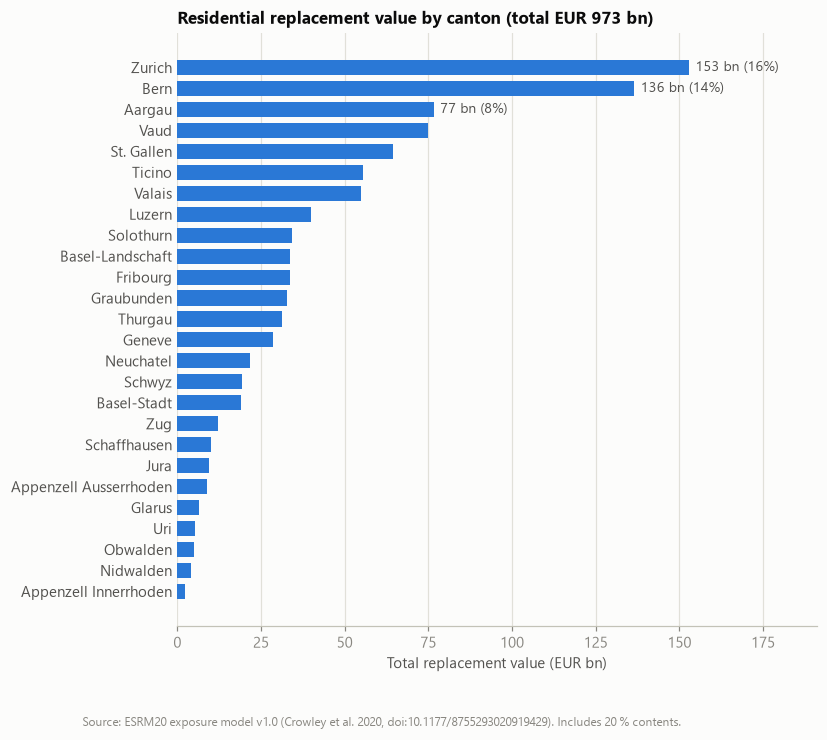

In [2]:
cant = value_by_canton(exposure).sort_values("value")
total = cant["value"].sum()

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(cant.index, cant["value"] / 1e9, height=0.72, color=ACCENT)
ax.xaxis.grid(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0, labelcolor=INK2)
for name in cant.index[-3:]:  # label only the three largest
    v = cant.loc[name, "value"]
    ax.text(v / 1e9 + 2, name, f"{v / 1e9:,.0f} bn ({v / total:.0%})", va="center",
            fontsize=9, color=INK2)
ax.set_xlim(0, cant["value"].max() / 1e9 * 1.25)
ax.set_xlabel("Total replacement value (EUR bn)")
ax.set_title(f"Residential replacement value by canton (total EUR {total / 1e9:,.0f} bn)")
fig.text(0.01, -0.02, "Source: ESRM20 exposure model v1.0 (Crowley et al. 2020, "
         "doi:10.1177/8755293020919429). Includes 20 % contents.", fontsize=8, color=MUTED)
fig.savefig(FIG / "m1_value_by_canton.png")
plt.show()

## M1: vulnerability

One panel per intensity measure, because a loss ratio at 0.3 g of PGA is not comparable to one at 0.3 g of SA(1.0). Grey: every ESRM20 function used by a Swiss residential class. Blue: the class carrying the most replacement value in that panel, with a ±1 standard-deviation band from the published CoV (the secondary uncertainty).

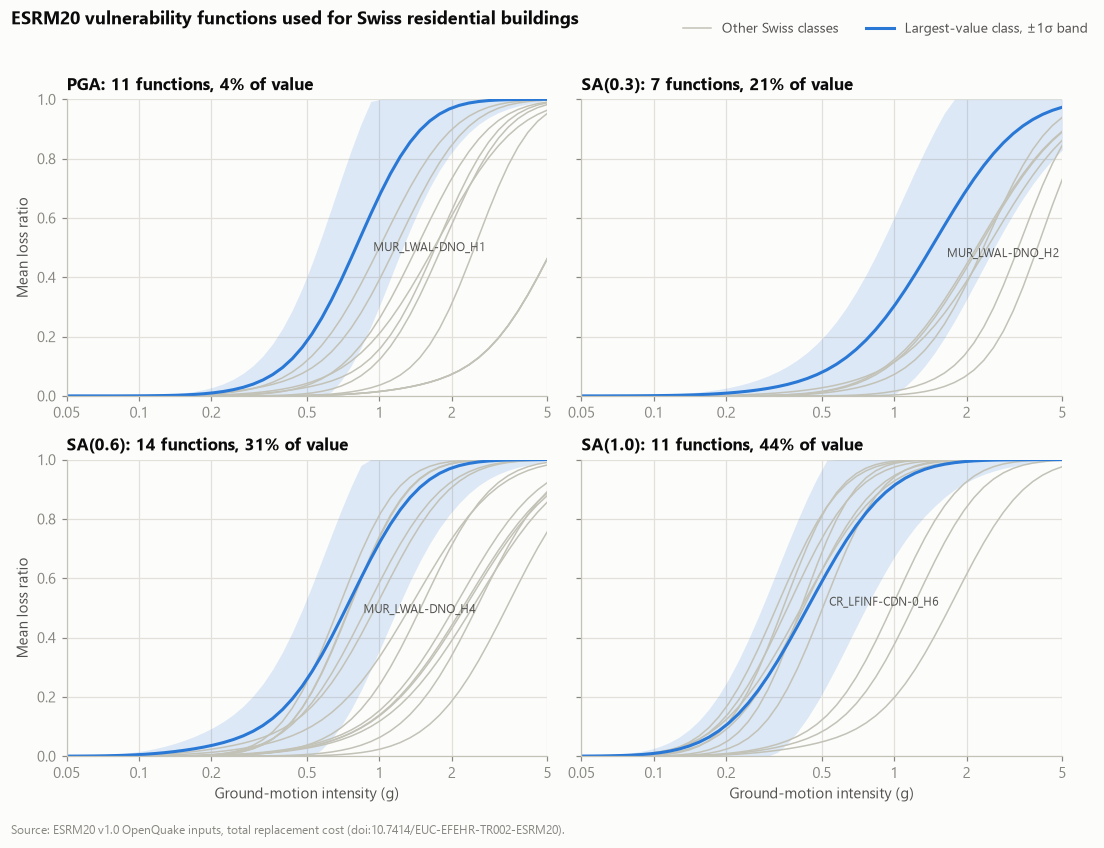

In [3]:
value_by_func = exposure.groupby(func)["value"].sum()
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2), sharey=True)
for ax, imt in zip(axes.flat, ["PGA", "SA(0.3)", "SA(0.6)", "SA(1.0)"], strict=True):
    used = [f for f in value_by_func.index if vuln.imt[f] == imt]
    for f in used:
        ax.plot(vuln.iml, vuln.mean[f], color=CONTEXT, lw=1)
    top = max(used, key=value_by_func.get)
    m = vuln.mean[top]
    s = vuln.cov[top] * m
    ax.fill_between(vuln.iml, np.clip(m - s, 0, 1), np.clip(m + s, 0, 1),
                    color=ACCENT, alpha=0.15, lw=0)
    ax.plot(vuln.iml, m, color=ACCENT, lw=2)
    i = int(np.argmax(m >= 0.5)) if m.max() >= 0.5 else len(m) - 1
    ax.annotate(vuln.ids[top], (vuln.iml[i], m[i]), xytext=(8, -10),
                textcoords="offset points", fontsize=8, color=INK2)
    share = value_by_func[used].sum() / value_by_func.sum()
    ax.set_title(f"{imt}: {len(used)} functions, {share:.0%} of value")
    ax.set_xscale("log")
    ax.set_xlim(0.05, 5)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_locator(FixedLocator([0.05, 0.1, 0.2, 0.5, 1, 2, 5]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(FixedLocator([]))
    ax.grid(True)
for ax in axes[1]:
    ax.set_xlabel("Ground-motion intensity (g)")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean loss ratio")
handles = [Line2D([], [], color=CONTEXT, lw=1, label="Other Swiss classes"),
           Line2D([], [], color=ACCENT, lw=2, label="Largest-value class, ±1σ band")]
fig.legend(handles=handles, loc="upper right", frameon=False, ncol=2, fontsize=9,
           labelcolor=INK2, bbox_to_anchor=(1.0, 1.02))
fig.suptitle("ESRM20 vulnerability functions used for Swiss residential buildings",
             x=0.01, ha="left", fontsize=12, fontweight="bold", y=1.02)
fig.tight_layout()
fig.text(0.01, -0.02, "Source: ESRM20 v1.0 OpenQuake inputs, total replacement cost "
         "(doi:10.7414/EUC-EFEHR-TR002-ESRM20).", fontsize=8, color=MUTED)
fig.savefig(FIG / "m1_vulnerability_curves.png")
plt.show()

## M2/M3 setup

The cells below read the outputs of `python run.py`, `python scripts/historical_rates.py` and `python scripts/sensitivity.py`; they compute nothing new except plotting summaries.

In [4]:
import pandas as pd
from matplotlib.colors import LogNorm

from chquake.catalogue import exposure_region, load_zone, modelled_rates
from chquake.metrics import (
    bootstrap_ci,
    convergence,
    ep_table,
    exceedance_curve,
    return_period_loss,
)

OUT = ROOT / cfg["run"]["output_dir"]
N_YEARS = cfg["run"]["n_years"]
events = pd.read_csv(OUT / "elt.csv")
ylt = pd.read_csv(OUT / "ylt.csv", index_col=0)
v = cfg["validation"]
zone, _ = load_zone(RAW / v["completeness_zones"], RAW / v["completeness_table"], v["zone"])
region = exposure_region(exposure, zone)
print(f"{len(events):,} events in {N_YEARS:,} years")

107,611 events in 50,000 years


## M2: event set vs the historical catalogue

Annual rate of earthquakes with magnitude ≥ M and epicentre in Switzerland (exposure hull clipped to ESHM20 completeness zone SZ02). Line: our 50,000-year event set. Points: declustered ESHM20 unified catalogue, each counted only over its complete period (e.g. M ≥ 5 since 1685), with exact 90 % Poisson intervals. This checks that the event generator reproduces the source model and that the source model is consistent with the local history; it was not tuned to fit.

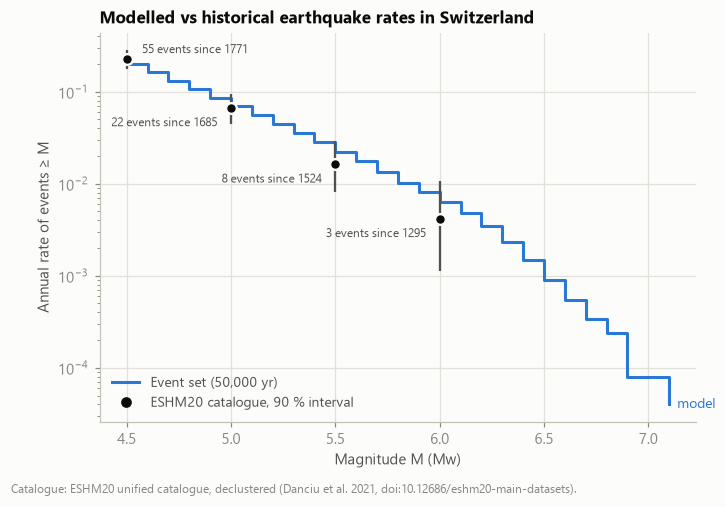

,from_year,years,n_events,rate,rate_lo90,rate_hi90,model_rate,model/obs
m_min,,,,,,,,
4.5,1771,244,55,0.2254,0.1779,0.2822,0.2009,0.8914
5.0,1685,330,22,0.0667,0.0451,0.0952,0.0697,1.0449
5.5,1524,491,8,0.0163,0.0081,0.0294,0.0221,1.3576
6.0,1295,720,3,0.0042,0.0011,0.0108,0.0063,1.5120


In [5]:
hist = pd.read_csv(OUT / "historical_rates.csv", index_col=0)
m_grid = np.round(np.arange(4.5, 7.55, 0.1), 2)
model = modelled_rates(events, N_YEARS, region, m_grid)
model = model[model > 0]

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(model.index, model.values, color=ACCENT, lw=2, drawstyle="steps-post")
yerr = [hist["rate"] - hist["rate_lo90"], hist["rate_hi90"] - hist["rate"]]
ax.errorbar(hist.index, hist["rate"], yerr=yerr, fmt="o", ms=7, color=INK, ecolor=INK2,
            elinewidth=1.5, capsize=0, mec=SURFACE, mew=1.5, zorder=3)
for i, (m, r) in enumerate(hist.iterrows()):
    # Below-left of the point stays clear of the falling model line (first point: no room left).
    xy, ha = ((10, 4), "left") if i == 0 else ((-9, -12), "right")
    ax.annotate(f"{int(r.n_events)} events since {int(r.from_year)}", (m, r["rate"]),
                xytext=xy, textcoords="offset points", ha=ha, fontsize=8, color=INK2)
ax.text(model.index[-1], model.values[-1], "  model", color=ACCENT, fontsize=9, va="center")
ax.set_yscale("log")
ax.set_xlabel("Magnitude M (Mw)")
ax.set_ylabel("Annual rate of events ≥ M")
ax.grid(True, which="major")
ax.set_title("Modelled vs historical earthquake rates in Switzerland")
handles = [Line2D([], [], color=ACCENT, lw=2, label=f"Event set ({N_YEARS:,} yr)"),
           Line2D([], [], color=INK, marker="o", ls="", label="ESHM20 catalogue, 90 % interval")]
ax.legend(handles=handles, frameon=False, fontsize=9, labelcolor=INK2, loc="lower left")
fig.text(0.01, -0.03, "Catalogue: ESHM20 unified catalogue, declustered (Danciu et al. 2021, "
         "doi:10.12686/eshm20-main-datasets).", fontsize=8, color=MUTED)
fig.savefig(FIG / "m2_rates_vs_catalogue.png")
plt.show()
hist.round(4)

## M2: where the loss comes from

Each simulated event's loss, summed into hexagonal cells by epicentre and divided by the number of years: the AAL contribution of earthquakes starting in that cell. Grey dots are the exposure points. The Basel area dominates: high source rates (the 1356 earthquake's zone) next to a dense, valuable building stock.

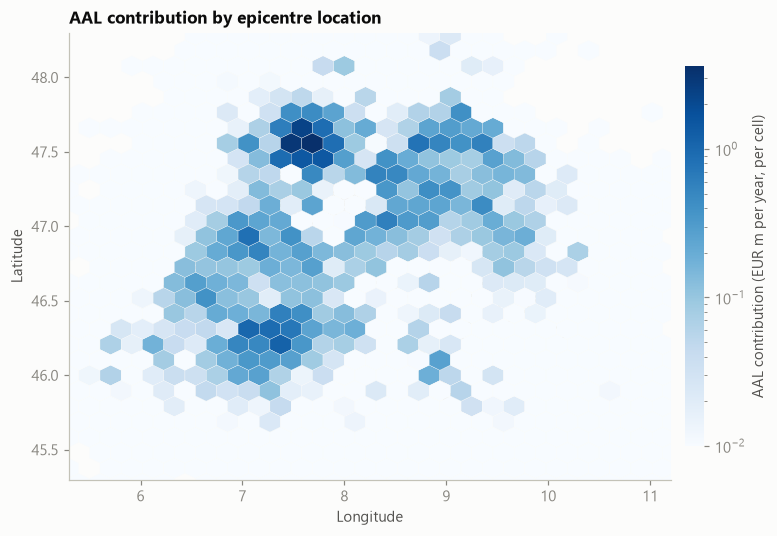

source
mainasz_combinedCHAS071    0.282
mainasz_combinedCHAS062    0.127
mainasz_combinedCHAS067    0.121
mainasz_combinedCHAS069    0.106
mainasz_combinedCHAS073    0.095
Name: loss, dtype: float64

In [6]:
hit = events[events["loss"] > 0]
pts = exposure.drop_duplicates(["lon", "lat"])
fig, ax = plt.subplots(figsize=(8.5, 5.6))
ax.scatter(pts["lon"], pts["lat"], s=1, color=CONTEXT, zorder=1)
hb = ax.hexbin(hit["lon"], hit["lat"], C=hit["loss"] / N_YEARS / 1e6, reduce_C_function=np.sum,
               gridsize=45, cmap="Blues", norm=LogNorm(vmin=0.01), mincnt=1, linewidths=0.2,
               edgecolors=SURFACE, zorder=2)
cb = fig.colorbar(hb, ax=ax, shrink=0.8, pad=0.02)
cb.set_label("AAL contribution (EUR m per year, per cell)", color=INK2)
cb.outline.set_visible(False)
ax.set_aspect(1 / np.cos(np.radians(46.8)))
ax.set_xlim(5.3, 11.2)
ax.set_ylim(45.3, 48.3)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("AAL contribution by epicentre location")
fig.savefig(FIG / "m2_aal_by_epicentre.png")
plt.show()
share = events.groupby("source")["loss"].sum().sort_values(ascending=False) / events["loss"].sum()
share.head(5).round(3)

## M3: exceedance-probability curves

OEP: the largest single-event loss in a year. AEP: the sum of all event losses in a year. Return period = 1 / annual exceedance frequency (empirical, k/N). The two nearly coincide because damaging years almost always contain one dominant event. Error bars: 90 % bootstrap interval (resampling years) on the OEP, i.e. Monte Carlo noise only, not model uncertainty.

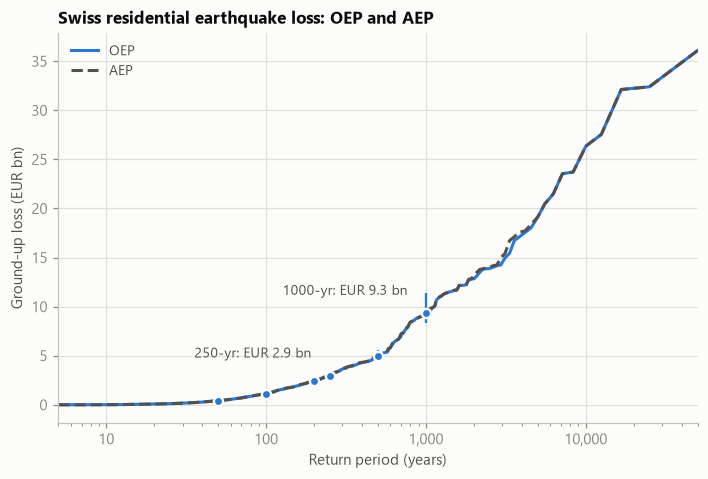

,OEP,AEP,TVaR_OEP,TVaR_AEP
return_period,,,,
50,0.42,0.42,2.40,2.42
100,1.14,1.15,4.10,4.14
200,2.40,2.46,6.50,6.56
250,2.94,3.01,7.46,7.53
500,4.95,5.07,11.06,11.14
1000,9.33,9.34,15.26,15.39


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for col, color, ls, label in [("max_loss", ACCENT, "-", "OEP"), ("agg_loss", INK2, "--", "AEP")]:
    loss, freq = exceedance_curve(ylt[col].to_numpy())
    keep = 1 / freq >= 5
    ax.plot(1 / freq[keep], loss[keep] / 1e9, color=color, lw=2, ls=ls, label=label)
rng = np.random.default_rng(0)
table = ep_table(ylt)
for rp in table.index:
    lo, hi = bootstrap_ci(ylt["max_loss"].to_numpy(), rp, rng, n_boot=300)[f"loss_{rp}"]
    y = table.loc[rp, "OEP"]
    ax.errorbar(rp, y / 1e9, yerr=[[(y - lo) / 1e9], [(hi - y) / 1e9]], fmt="o",
                ms=6, color=ACCENT, ecolor=ACCENT, mec=SURFACE, mew=1.5, capsize=0)
for rp in (250, 1000):
    y = table.loc[rp, "OEP"] / 1e9
    ax.annotate(f"{rp}-yr: EUR {y:.1f} bn", (rp, y), xytext=(-12, 12), textcoords="offset points",
                ha="right", fontsize=9, color=INK2)
ax.set_xscale("log")
ax.set_xlim(5, N_YEARS)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Return period (years)")
ax.set_ylabel("Ground-up loss (EUR bn)")
ax.grid(True)
ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc="upper left")
ax.set_title("Swiss residential earthquake loss: OEP and AEP")
fig.savefig(FIG / "m3_ep_curves.png")
plt.show()
(table / 1e9).round(2)

## M3: convergence

Each metric recomputed from the first n simulated years only. A metric is usable once its running estimate stays inside the final 90 % bootstrap band (shaded). The tail converges far more slowly than the mean: the 250-year loss uses only the 200 worst of 50,000 years.

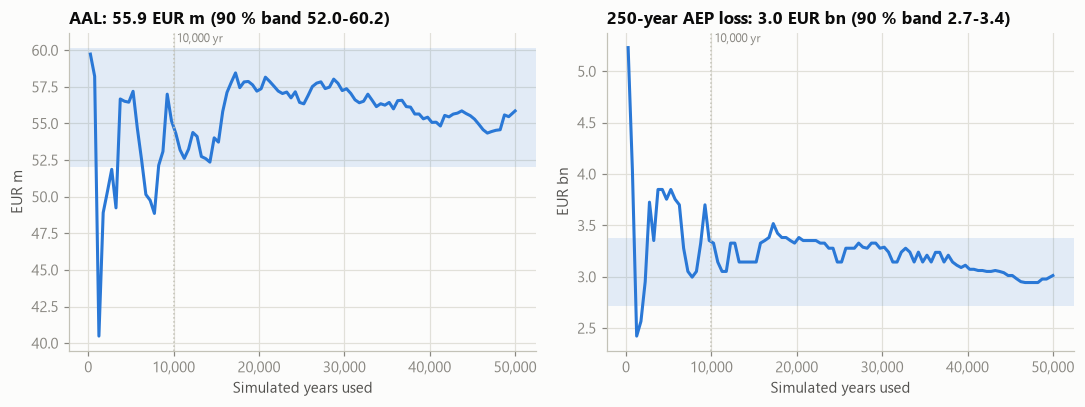

In [8]:
agg = ylt["agg_loss"].to_numpy()
conv = convergence(agg, rp=250, n_points=100)
ci = bootstrap_ci(agg, 250, np.random.default_rng(1), n_boot=300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, key, label, scale, unit in [
    (axes[0], "aal", "aal", "AAL", 1e6, "EUR m"),
    (axes[1], "loss_250", "loss_250", "250-year AEP loss", 1e9, "EUR bn"),
]:
    lo, hi = (x / scale for x in ci[key])
    ax.axhspan(lo, hi, color=ACCENT, alpha=0.12, lw=0)
    ax.plot(conv["n_years"], conv[col] / scale, color=ACCENT, lw=2)
    ax.axvline(10_000, color=CONTEXT, lw=1, ls=":")
    ax.text(10_000, ax.get_ylim()[1], " 10,000 yr", fontsize=8, color=MUTED, va="top")
    ax.set_title(f"{label}: {conv[col].iloc[-1] / scale:,.1f} {unit} "
                 f"(90 % band {lo:,.1f}-{hi:,.1f})")
    ax.set_xlabel("Simulated years used")
    ax.set_ylabel(unit)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIG / "m3_convergence.png")
plt.show()

## M4: ground-up → gross → net

Annual aggregate loss (AEP) at three stages. **Gross**: after the per-building deductible of the Swiss earthquake pool statutes (10 % of value, at least CHF 50,000; buildings only, no contents). **Net**: gross minus the recoveries of the illustrative cat XL layer (band), with one reinstatement. The deductible removes most of the frequent losses; the layer flattens the curve between its attachment and exhaustion and does nothing beyond.

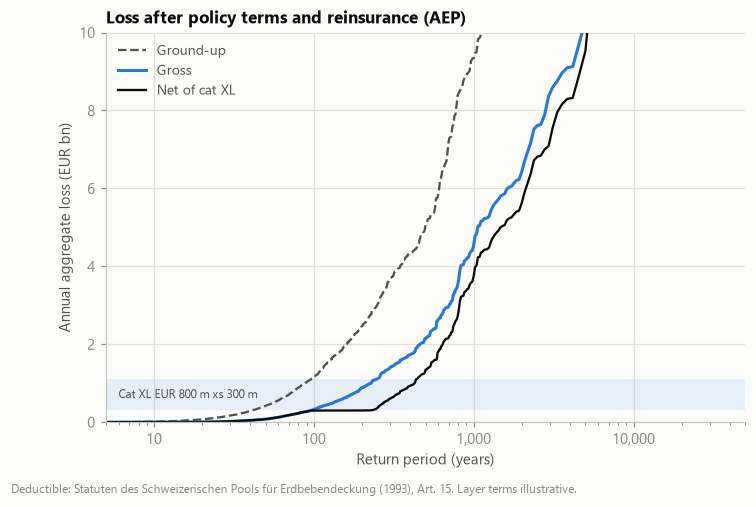

,Ground-up,Gross,Net of cat XL
AAL,56.0,20.0,15.0
AEP_100,1155.0,326.0,300.0
AEP_250,3012.0,1110.0,370.0
AEP_1000,9339.0,4545.0,3745.0


expected_recovery    5.070679e+06
pure_premium         5.038932e+06
rate_on_line         6.300000e-03
p_attach             1.040000e-02
p_exhaust            0.000000e+00
std_recovery         5.872422e+07
Name: value, dtype: float64

In [9]:
xl = cfg["financial"]["cat_xl"]
xl_ylt = pd.read_csv(OUT / "ylt_cat_xl.csv", index_col=0)
summary = pd.read_csv(OUT / "cat_xl_summary.csv", index_col=0)["value"]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.axhspan(xl["attachment"] / 1e9, (xl["attachment"] + xl["limit"]) / 1e9, color=ACCENT,
           alpha=0.10, lw=0)
ax.text(6, (xl["attachment"] + xl["limit"] / 2) / 1e9,
        f"Cat XL EUR {xl['limit'] / 1e6:,.0f} m xs {xl['attachment'] / 1e6:,.0f} m",
        fontsize=8, color=INK2, va="center")
curves = [(ylt["agg_loss"], INK2, "--", 1.5, "Ground-up"),
          (xl_ylt["gross"], ACCENT, "-", 2, "Gross"),
          (xl_ylt["net"], INK, "-", 1.5, "Net of cat XL")]
for annual, color, ls, lw, label in curves:
    loss, freq = exceedance_curve(annual.to_numpy())
    keep = 1 / freq >= 5
    ax.plot(1 / freq[keep], loss[keep] / 1e9, color=color, ls=ls, lw=lw, label=label)
ax.set_xscale("log")
ax.set_xlim(5, N_YEARS)
ax.set_ylim(0, 10)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Return period (years)")
ax.set_ylabel("Annual aggregate loss (EUR bn)")
ax.grid(True)
ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc="upper left")
ax.set_title("Loss after policy terms and reinsurance (AEP)")
fig.text(0.01, -0.03, "Deductible: Statuten des Schweizerischen Pools für Erdbebendeckung "
         "(1993), Art. 15. Layer terms illustrative.", fontsize=8, color=MUTED)
fig.savefig(FIG / "m4_gross_net.png")
plt.show()
stages = pd.DataFrame({
    label: {"AAL": annual.mean(),
            **{f"AEP_{rp}": return_period_loss(annual, rp) for rp in (100, 250, 1000)}}
    for annual, *_, label in curves
})
display((stages / 1e6).round(0))
summary.round(4)

## M2/M3: sensitivity to modelling choices

One choice changed at a time, everything else (including every random draw) identical: common random numbers. Change relative to the baseline. Differences of a few percent in the 1,000-year loss are within Monte Carlo noise (only 50 years define it).

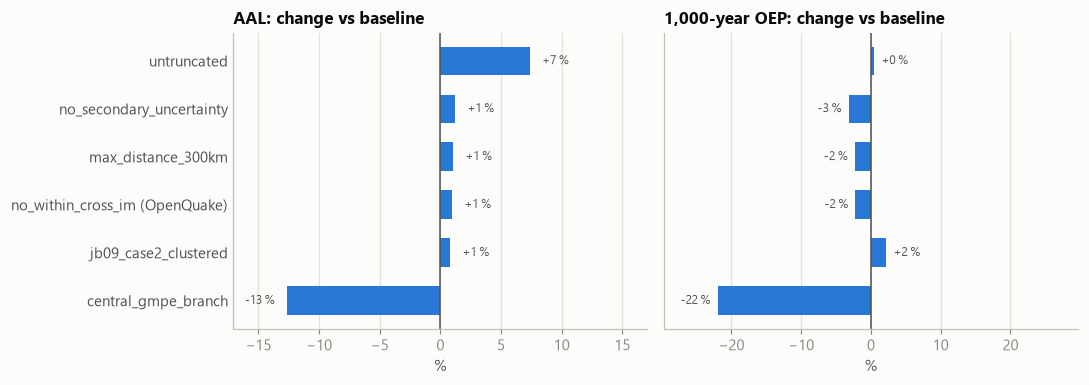

,AAL,OEP_100,OEP_250,OEP_1000,AEP_200,TVaR_AEP_100,gross_AAL,gross_OEP_100,gross_OEP_250,gross_OEP_1000
baseline,56.0,1142.0,2944.0,9331.0,2460.0,4136.0,20.0,323.0,1109.0,4545.0
max_distance_300km,56.0,1184.0,3153.0,9117.0,2546.0,4180.0,NaN,NaN,NaN,NaN
no_within_cross_im (OpenQuake),56.0,1172.0,2945.0,9123.0,2406.0,4117.0,NaN,NaN,NaN,NaN
jb09_case2_clustered,56.0,1161.0,3251.0,9538.0,2629.0,4239.0,NaN,NaN,NaN,NaN
no_secondary_uncertainty,57.0,1204.0,3149.0,9033.0,2588.0,4179.0,NaN,NaN,NaN,NaN
central_gmpe_branch,49.0,1043.0,2616.0,7280.0,2195.0,3579.0,NaN,NaN,NaN,NaN
untruncated,60.0,1271.0,3132.0,9376.0,2656.0,4410.0,NaN,NaN,NaN,NaN
values_x2.43 (ERM-CH23 total),136.0,2775.0,7153.0,22674.0,5978.0,10052.0,57.0,1001.0,3224.0,12136.0


In [10]:
sens = pd.read_csv(OUT / "sensitivity.csv", index_col=0)
hazard = [i for i in sens.index if not i.startswith("values_")]  # exposure case: see M4
rel = (sens.loc[hazard] / sens.loc["baseline"] - 1).drop("baseline").sort_values("AAL")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, label in [(axes[0], "AAL", "AAL"), (axes[1], "OEP_1000", "1,000-year OEP")]:
    ax.barh(rel.index, rel[col] * 100, height=0.6, color=ACCENT)
    ax.axvline(0, color=INK2, lw=1)
    for name, x in (rel[col] * 100).items():
        ax.text(x + (1 if x >= 0 else -1), name, f"{x:+.0f} %", va="center",
                ha="left" if x >= 0 else "right", fontsize=8, color=INK2)
    lim = max(abs(rel[col]).max() * 100 * 1.35, 5)
    ax.set_xlim(-lim, lim)
    ax.set_title(f"{label}: change vs baseline")
    ax.set_xlabel("%")
    ax.xaxis.grid(True)
    ax.tick_params(axis="y", length=0, labelcolor=INK2)
fig.tight_layout()
fig.savefig(FIG / "m3_sensitivity.png")
plt.show()
(sens / 1e6).round(0)